# DC4 511 keV Imaging and Residual Analysis

This notebook runs the complete imaging workflow in one kernel: it combines the weekly observations, prepares the simulated background and detector response, reconstructs the 511 keV sky, evaluates the fitted source and background expectations, and calculates residual diagnostics directly from the in-memory histograms. No intermediate residual-product file is required.

In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Environment and imports

The following cells locate the workflow directory, import the imaging and residual-analysis interfaces, and load the centralized input paths.

In [29]:
# Locate the workflow root so local modules can be imported.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent 
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [30]:
import numpy as np
import cosipy as cp
import matplotlib.pyplot as plt

from cosipy.image_deconvolution import DataIF_COSI_DC2, ImageDeconvolution
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
import healpy as hp
from histpy import Histogram
import astropy.units as u
from astromodels import DiracDelta
from IPython.display import display
from src.convoluton_imager import plot_reconstructed_image

%matplotlib inline

### 1.1 Input paths and DATAIO configuration

All input locations come from `src.path_to_files`. Inspecting the key paths here makes missing or misplaced products fail early, before the expensive reconstruction starts.

In [31]:
# Input products: add all paths used by this analysis. See `workflow/src/path_to_files.py`.
from src import path_to_files as paths

In [32]:
# Display the main response and weekly-output locations.
print(paths.data_ext_response511_path)
print(paths.data_dir_out)

/Users/maura/Documents/COSI/data-challenge-4/workflow/data/inputs/extended_source_response_511_merged.h5
/Users/maura/Documents/COSI/data-challenge-4/workflow/data/outputs


In [33]:
# Select the DATAIO configuration for the 511 keV event files.
yaml_conf = paths.config_511_path
yaml_conf

PosixPath('/Users/maura/Documents/COSI/data-challenge-4/workflow/data/config/dataio_511.yaml')

## 2. Observed 511 keV data

Each weekly product contains a time-resolved event histogram. The full weekly `(Time, Em, Phi, PsiChi)` histograms are added first to retain `Observed_temporal_counts` ($D_{t,i}$). Projecting out time then gives `observed_atemporal_counts` ($D_i$), used by the imaging fit through the existing `observed_event_hist` name.

In [34]:
# Load every weekly binned observation.
analysis511 = {}

for week in paths.weekly_paths:
    output_prefix = paths.data_dir_out / f"dc4_week_{week}_511_binned"
    output_path = output_prefix.with_suffix(".hdf5")

    analysis511[week] = cp.BinnedData(yaml_conf)
    analysis511[week].load_binned_data_from_hdf5(
        binned_data=str(output_path)
    )
    analysis511[week].get_binning_info()

In [35]:
# Copy the first full histogram to preserve the original weekly data.
observed_weeks = list(paths.weekly_paths)
Observed_temporal_counts = analysis511[observed_weeks[0]].binned_data.copy()

# Add counts only when all time and CDS bins match exactly.
for week in observed_weeks[1:]:
    week_hist = analysis511[week].binned_data
    if week_hist.axes != Observed_temporal_counts.axes:
        raise ValueError(f"Week {week} has incompatible time or CDS bins.")
    # Use out-of-place addition to preserve sparse histogram contents.
    Observed_temporal_counts = Observed_temporal_counts + week_hist

# Sum over time only after combining the full temporal histograms.
observed_atemporal_counts = (
    Observed_temporal_counts
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

# Keep the imaging workflow connected to the atemporal counts.
observed_event_hist = observed_atemporal_counts

print("Observed temporal axes:", Observed_temporal_counts.axes.labels)
print("Observed temporal shape:", Observed_temporal_counts.shape)
print("Observed axes:", observed_event_hist.axes.labels)
print("Observed shape:", observed_event_hist.shape)
print("Observed total counts:", observed_event_hist.contents.sum())

Observed temporal axes: ['Time' 'Em' 'Phi' 'PsiChi']
Observed temporal shape: (2217, 1, 60, 3072)
Observed axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Observed total counts: 1576953.0


## 3. Simulated background

The background-only simulation is projected onto the same CDS axes as the observation. Its normalization remains part of the image-deconvolution result.

In [36]:
simulated_background = cp.BinnedData(paths.config_511_path)
simulated_background.load_binned_data_from_hdf5(
    binned_data=str(paths.simulated_background_511_binned_path)
)
simulated_background.get_binning_info()

simulated_background_hist = (
    simulated_background.binned_data
)

In [37]:
# Remove any auxiliary axes while retaining the CDS coordinates.
simulated_bg_counts_all = (
    simulated_background_hist
    .project( "Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

print("Background axes:", simulated_bg_counts_all.axes.labels)
print("Background shape:", simulated_bg_counts_all.shape)

Background axes: ['Em' 'Phi' 'PsiChi']
Background shape: (1, 60, 3072)


## 4. Imaging response and data interface

The precomputed Galactic response and the observed/background histograms are combined in the COSI image-deconvolution data interface. Matching axes and shapes are checked before fitting.

In [38]:
# Load the precomputed extended-source response.
response_511 = Histogram.open(
    str(paths.data_ext_response511_path)
)

In [39]:
# Verify that observed and background counts use identical CDS bins.
if observed_event_hist.axes != simulated_bg_counts_all.axes:
    raise ValueError("Observed and background histograms have incompatible axes.")

if observed_event_hist.shape != simulated_bg_counts_all.shape:
    raise ValueError("Observed and background histograms have incompatible shapes.")

data_interface = DataIF_COSI_DC2.load(
    name="511keV",
    event_binned_data=observed_event_hist,
    dict_bkg_binned_data={"background": simulated_bg_counts_all},
    rsp=response_511,
    coordsys_conv_matrix=None,
)

In [40]:
# Select the image-deconvolution configuration.
yml_file = paths.config_deconvo_path

In [41]:
# Configure the reconstruction with the simulated-background dataset.
image_deconvolution = ImageDeconvolution()

# Register the prepared data interface.
image_deconvolution.set_dataset([data_interface])
# Load the reconstruction parameters.
image_deconvolution.read_parameterfile(yml_file)

## 5. Image deconvolution

This is the computational fit. The final iteration contains both the reconstructed sky image and the fitted background normalization required to evaluate the expected CDS counts.

In [42]:
image_deconvolution.initialize()
image_deconvolution.run_deconvolution()
image_deconvolution.results

  0%|          | 0/15 [00:00<?, ?it/s]

[{'iteration': 1,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x124b4d550>,
  'background_normalization': {'background': 1.0961076123758495},
  'log-likelihood': [2266291.1040600436],
  'accel_factor': 1.0},
 {'iteration': 2,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x124ce2f50>,
  'background_normalization': {'background': 1.0952079248005853},
  'log-likelihood': [2267105.066573919],
  'accel_factor': 10.0},
 {'iteration': 3,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x124ce22d0>,
  'background_normalization': {'background': 1.0863005902917515},
  'log-likelihood': [2268141.8285720265],
  'accel_factor': 10.0},
 {'iteration': 4,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x124b07750>,
  'background_normalization': {'background': 1.0777807213964938},
  'log-likelihood': [2269398.1521391096],
  'accel_factor': 10.0},
 {'iteration': 5,
  'model': <

## 7. Evaluate the fitted CDS expectation

The final reconstruction provides the fitted sky image and background normalization. Folding these fitted quantities through the same data interface produces the source, background, and total expected counts in exactly the observed `(Em, Phi, PsiChi)` bins.

In [43]:
# Read the fitted quantities from the final reconstruction iteration.
final_result = image_deconvolution.results[-1]
fitted_image = final_result["model"]
fitted_background_norm = final_result["background_normalization"]

# Fold the fitted sky and background models into the observed CDS bins.
source_expectation = data_interface.calc_source_expectation(fitted_image)
background_expectation = data_interface.calc_bkg_expectation(
    fitted_background_norm
)
total_expectation = data_interface.calc_expectation(
    fitted_image,
    fitted_background_norm,
)

## 8. Residual analysis from in-memory histograms

`ResidualAnalysis` receives the integrated observation and the fitted total expectation directly. Unlike the file-based tutorial, this workflow does not call `Histogram.open()` because both histograms were produced in the current kernel.

In [44]:
# Associate the in-memory histograms explicitly with their analysis roles.
residual_analysis = ResidualAnalysis(
    observed=observed_event_hist,
    expected=total_expectation,
)

# Calculate one projected residual for direct numerical inspection.
phi_raw_residual = residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Residual axes:", phi_raw_residual.axes.labels)
print("Residual shape:", phi_raw_residual.shape)
print("Mask report:", residual_analysis.mask_report)

Observed data have no time information; using atemporal residual analysis.
Residual axes: ['Phi']
Residual shape: (60,)
Mask report: {'total_bins': 184320, 'valid_bins': np.int64(184320), 'excluded_bins': np.int64(0), 'observed_counts_excluded': np.float64(0.0), 'expected_floor': None, 'minimum_expected': <Quantity 1.e-12>, 'minimum_retained_expected': <Quantity 1.e-12>}


### 8.1 Time-integrated residual plots

`ResidualAnalysis` projects the observed and expected counts before computing residuals. Choose `residual_type="raw"` for D − M, `"pearson"` for (D − M)/√M, or `"fractional"` for (D − M)/M; normalized residuals require positive projected M.

The examples show a one-dimensional `Phi_projection` and angular `Phi_Chi_projection` maps. Other available projections can be inspected through `residual_analysis.projected_data()`. The Pearson figure without an uncertainty band illustrates `show_uncertainty=False`; `show_gaussian_reference` controls the standard-normal overlay. A nominal band or fixed-fit Poisson reference is not a calibrated goodness-of-fit test for DC4 shared-background data.


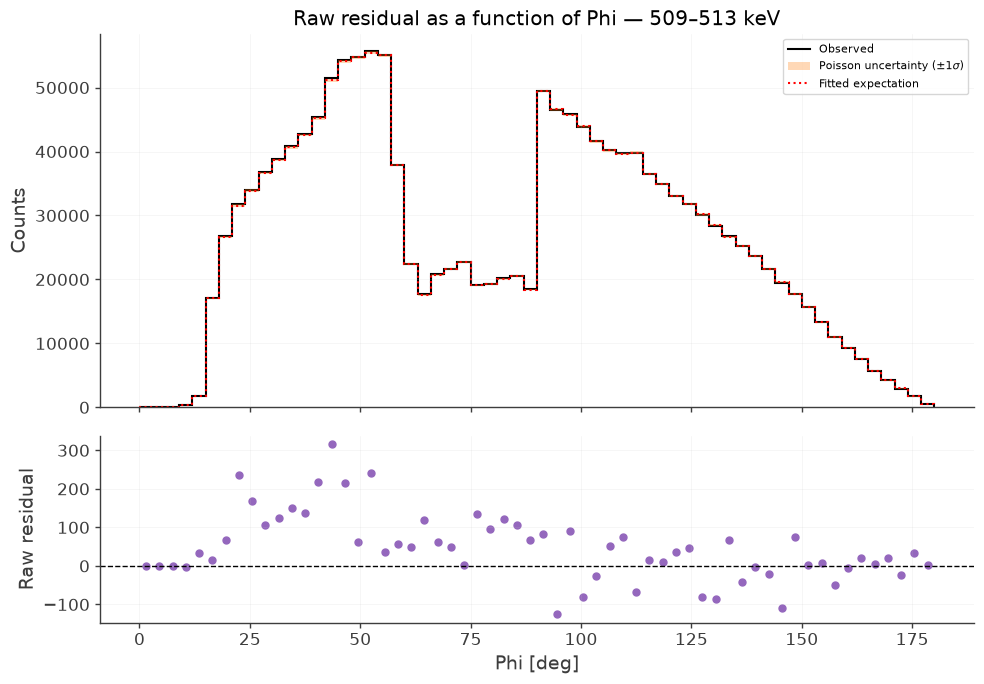


WARNING UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



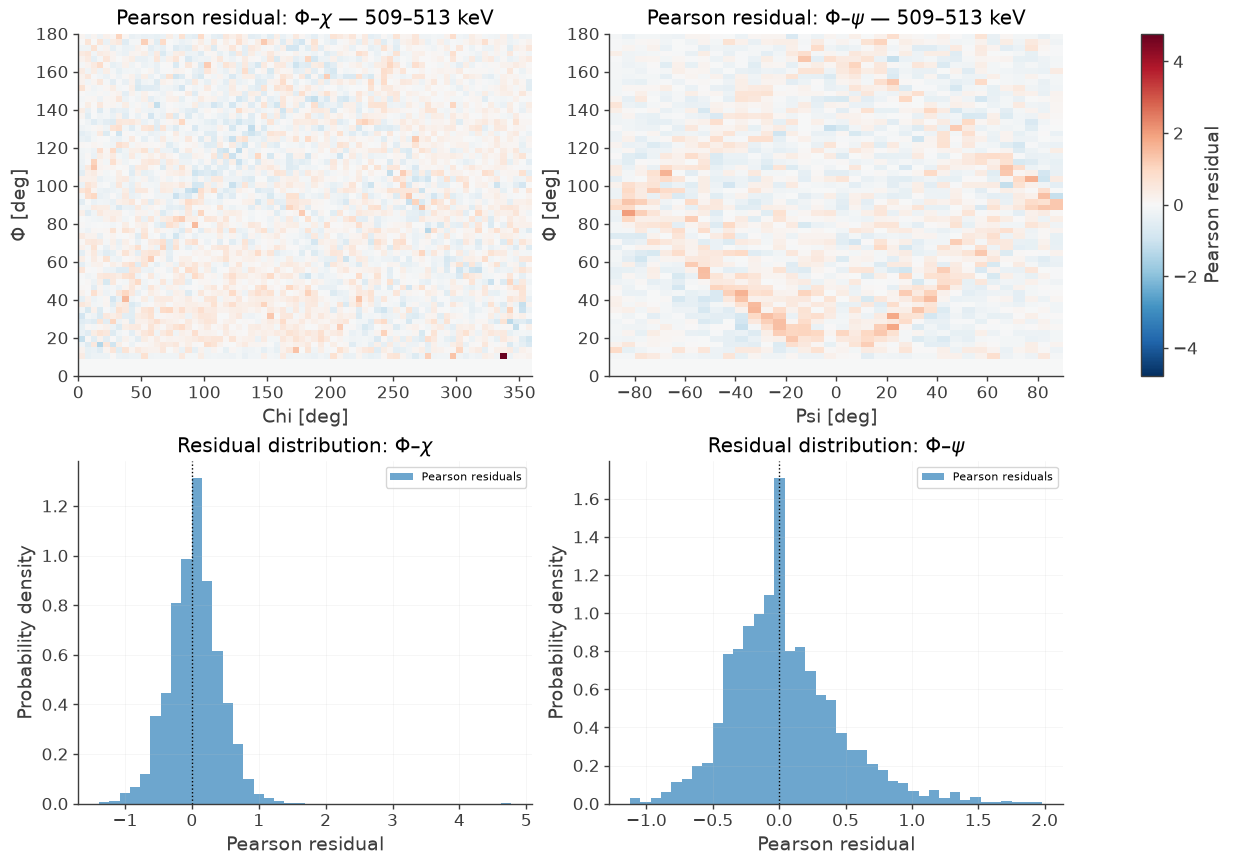

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,0.006158,-0.079596,0.445315,0.445357,-1.626413,17.35212,0.381402,0.212674,36558.590854,25525.814956


In [45]:
# Configure the plotting interface without Monte Carlo references.
residual_plotter = PlottingResiduals(residual_analysis)

# Compare observed and expected counts along the Phi projection.
phi_raw_figure = residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Inspect the angular residual maps in expectation-scaled units.
angular_pearson_figure = residual_plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

display(residual_analysis.statistics_table("pearson"))

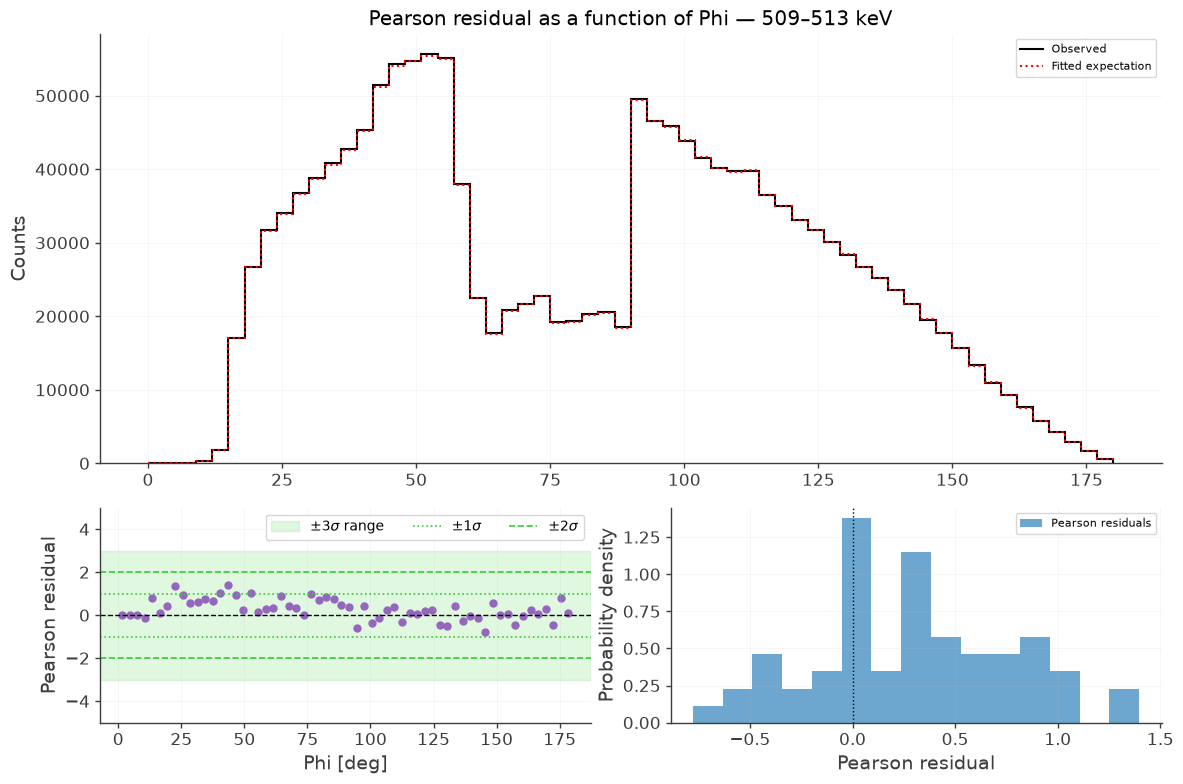

In [46]:
# Plot the same atemporal counts and pearson residual without the uncertainty band.
phi_pearson_without_band = residual_plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    show_uncertainty=False,
    show_gaussian_reference=False
)


## 9. Temporal residual analysis with a physical prediction

The fitted sky is folded through the detector response using the spacecraft orientation of each interval. The fitted normalization scales the time-binned simulated background. The prediction is provisional: response settings need further verification, and the simulated background can share events with the observed DC4 data.

In [47]:
# Import the temporal analysis class and time utilities.
from time import perf_counter
from src.time_resolved_residuals_v1 import TemporalPredictionBuilder

# Prepare the temporal class using the observed counts and integrated model axes.
physical_temporal_analysis = TemporalPredictionBuilder(
    observed=Observed_temporal_counts,
    integrated_expected=total_expectation,
)
orientation = cp.SpacecraftHistory.open(paths.data_ori_path)
print("Available time bins:", physical_temporal_analysis.observed_hist.axes["Time"].nbins)

Available time bins: 2217


In [48]:
# Configure the physical model once. Earth occultation remains provisional.
physical_temporal_analysis.configure_physical_model(
    fitted_sky=fitted_image,
    response_path=paths.data_response511_path,
    orientation=orientation,
    temporal_background=simulated_background_hist,
    background_normalization=fitted_background_norm["background"],
    earth_occ=True,
)

### 9.1 Build matching temporal histograms

Select consecutive bins using their original indices. The first index is included and the stop index is excluded. The class calculates missing bins and reuses predictions already held in memory; the first calculation can take several minutes. Call `configure_physical_model` again after changing any physical input or response setting, which clears the cached predictions. Restarting the kernel also clears them. The time-bin widths come from the input histograms.

In [49]:
# Select five consecutive bins; omit both arguments to request all available bins.
first_time_bin = 13
stop_time_bin = first_time_bin + 5
calculation_start = perf_counter()
selected_observed_temporal, selected_expected_temporal = (
    physical_temporal_analysis.build_physical_time_range(
        start=first_time_bin,
        stop=stop_time_bin,
    )
)
print("Selected original time bins:", first_time_bin, "to", stop_time_bin - 1)
print("Calculation time (seconds):", perf_counter() - calculation_start)

Selected original time bins: 13 to 17
Calculation time (seconds): 1115.7907128750085


### 9.2 Temporal counts and residual plots

`ResidualAnalysis` receives matching observed and physical expected time histograms. `Time_projection` compares counts and residuals in each selected interval; `select_time_bin` selects one already prepared interval for angular plots. The same `raw`, `pearson`, and `fractional` definitions apply after projection.

Physical temporal predictions have no uncertainty band by default. `show_uncertainty=True` displays a nominal Poisson band; `show_gaussian_reference` controls the standard-normal overlay for Pearson residuals. These are visual references, not calibrated uncertainty or a goodness-of-fit test for DC4 shared-background data. The physical prediction remains provisional and has not been shown to sum to the full integrated fit expectation.


In [50]:
# Initialize the temporal residual analysis with the prepared physical products.
temporal_analysis = ResidualAnalysis(
    observed=selected_observed_temporal,
    expected=selected_expected_temporal,
)
temporal_plotter = PlottingResiduals(temporal_analysis)


Observed data contain time information; using temporal residual analysis.


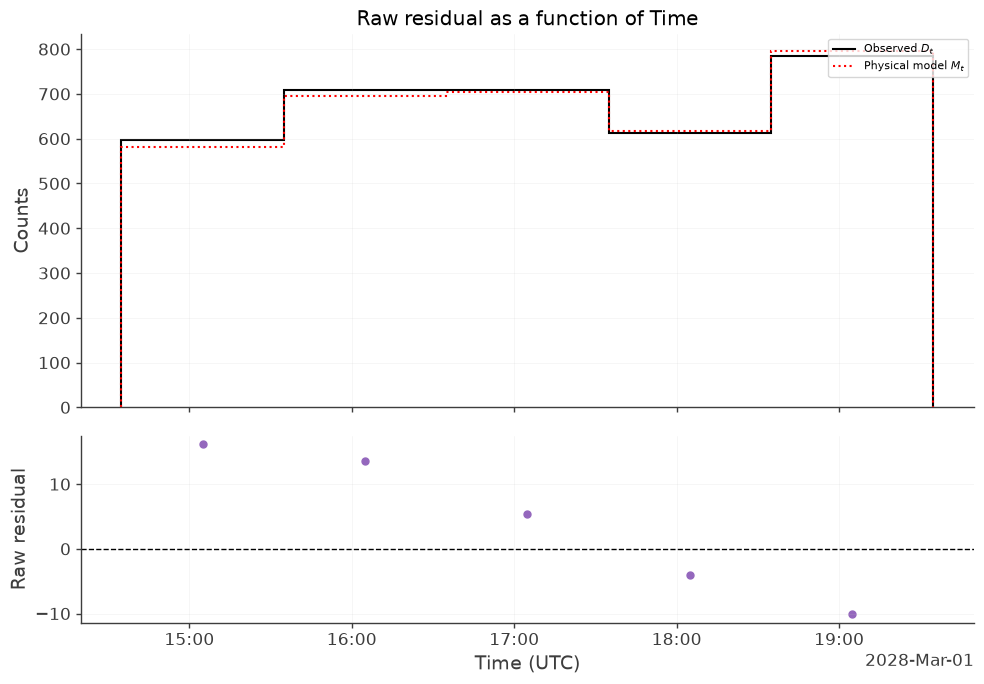

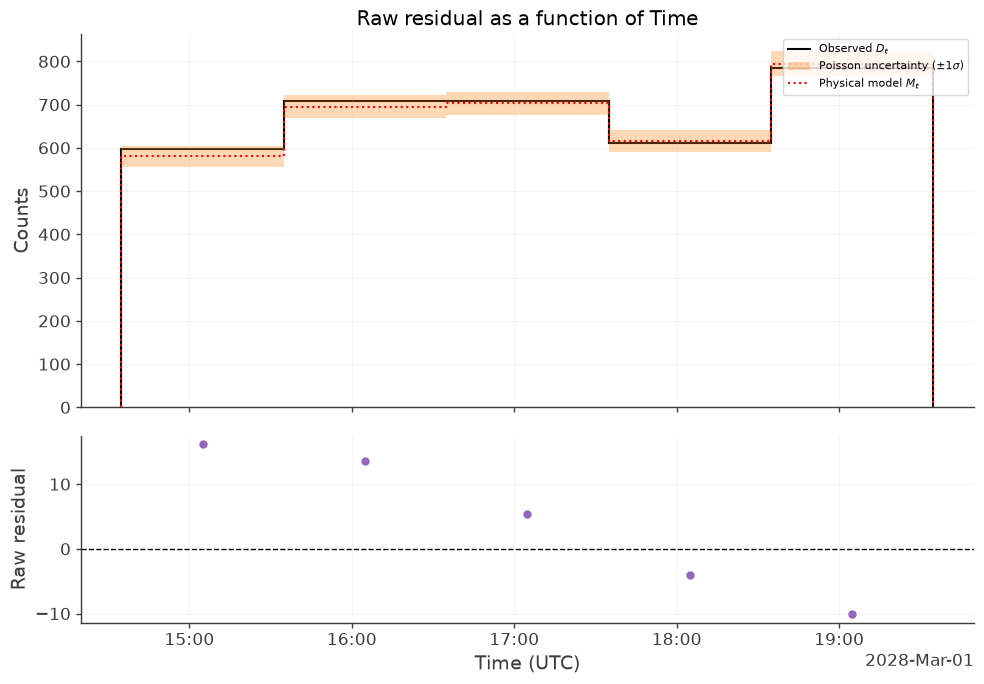

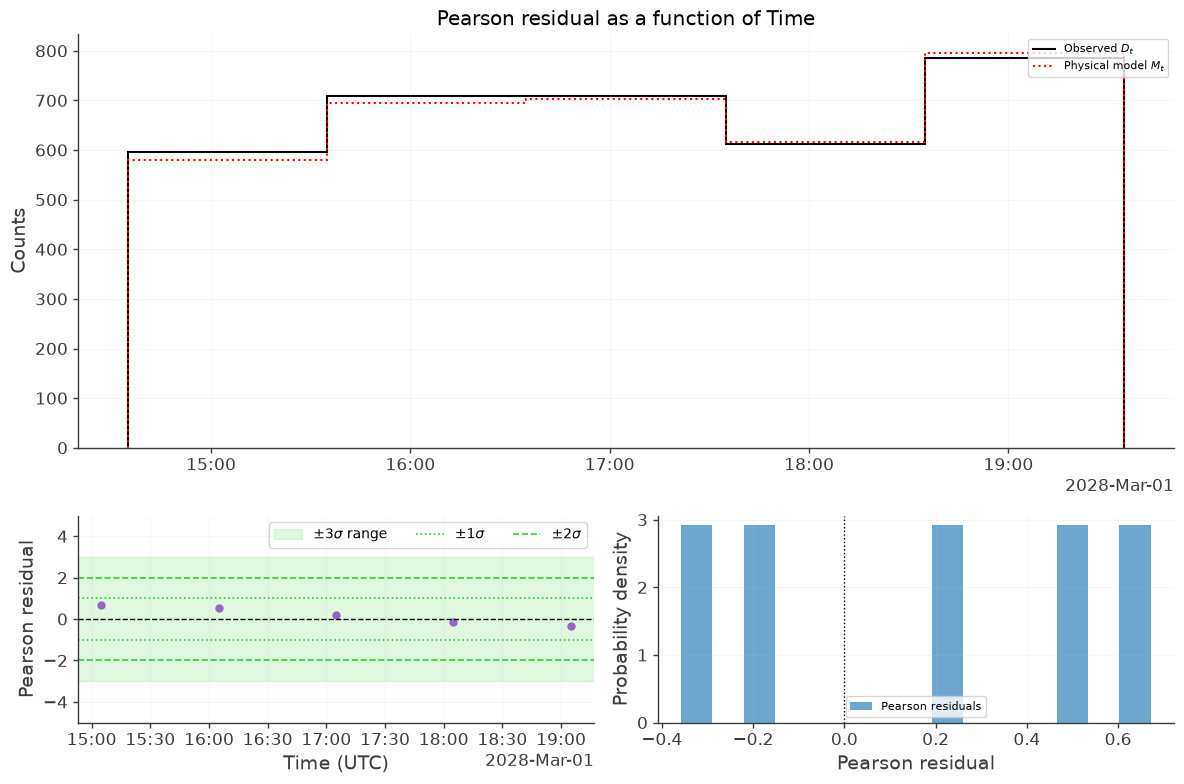

In [51]:
# Compare observed and expected counts and raw residuals over time, without a band.
time_raw_without_band = temporal_plotter.plot(
    "Time_projection",
    residual_type="raw",
    show_uncertainty=False,
)

# Show the optional nominal Poisson band for the same time projection.
time_raw_with_band = temporal_plotter.plot(
    "Time_projection",
    residual_type="raw",
    show_uncertainty=True,
)

# Inspect Pearson residuals and their distribution without a Gaussian reference.
time_pearson_figure = temporal_plotter.plot(
    "Time_projection",
    residual_type="pearson",
    show_uncertainty=False,
    show_gaussian_reference=False,
)


Subset time bin 0 corresponds to original time bin 13.


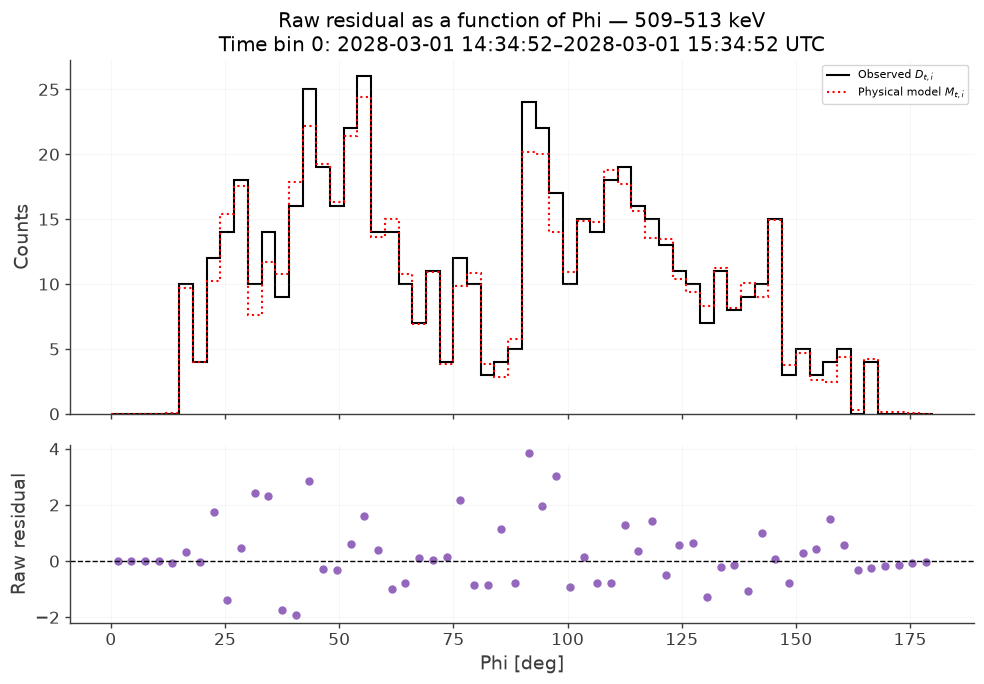

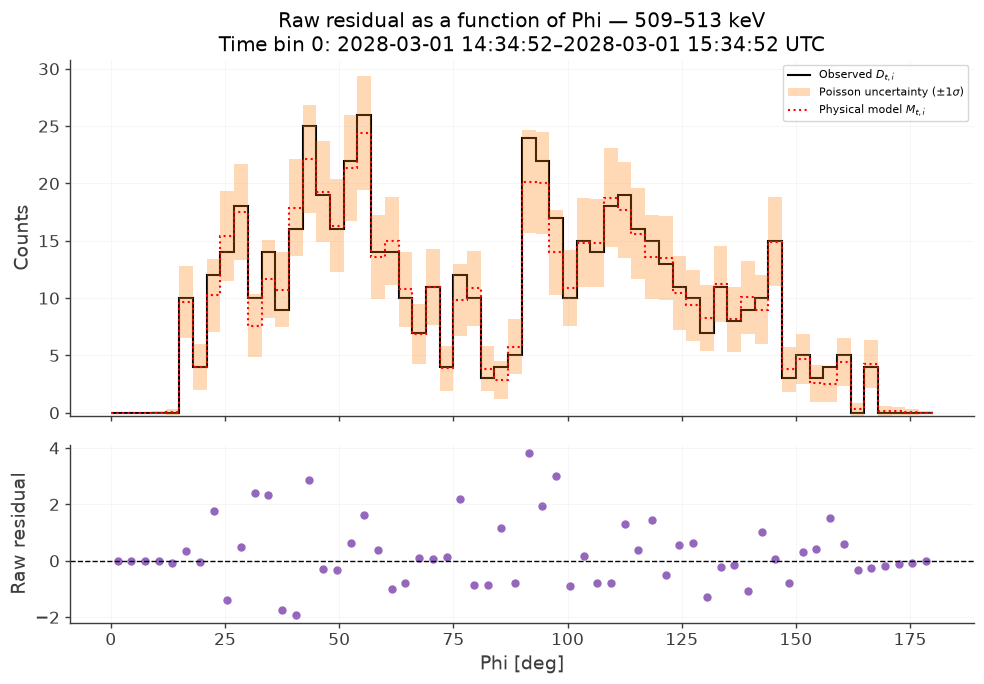

In [52]:
# Select the first interval of the five-bin temporal histogram without refolding.
selected_temporal_analysis = temporal_analysis.select_time_bin(0)
print(f"Subset time bin 0 corresponds to original time bin {first_time_bin}.")
selected_temporal_plotter = PlottingResiduals(selected_temporal_analysis)

# Compare observed and expected counts and raw residuals as a function of Phi.
selected_phi_without_band = selected_temporal_plotter.plot(
    "Phi_projection",
    residual_type="raw",
    show_uncertainty=False,
)

# Display the optional nominal Poisson band for the same selected interval.
selected_phi_with_band = selected_temporal_plotter.plot(
    "Phi_projection",
    residual_type="raw",
    show_uncertainty=True,
)
